In [5]:
import pandas as pd
import missingno as msno
from pymongo import MongoClient, InsertOne
from migration import migrate_data
from loading import load_data
from cleaning import clean_data

In [2]:
### FUNCTIONS
"""
def format_header(df:pd.DataFrame):
    col_names = list(df.columns)
    return {col:col.title().replace(" ","") for col in col_names} 

def drop_duplicates_w_criterias(df: pd.DataFrame):
    criterias = [
        "Name", "Gender",
        "DateOfAdmission", "DischargeDate",
        "BloodType", "BillingAmount",
        "RoomNumber", "Medication",
        "Hospital"
    ]

    df = df[~df[criterias].duplicated(keep=False)].reset_index(drop=True)
    return df
"""


'\ndef format_header(df:pd.DataFrame):\n    col_names = list(df.columns)\n    return {col:col.title().replace(" ","") for col in col_names} \n\ndef drop_duplicates_w_criterias(df: pd.DataFrame):\n    criterias = [\n        "Name", "Gender",\n        "DateOfAdmission", "DischargeDate",\n        "BloodType", "BillingAmount",\n        "RoomNumber", "Medication",\n        "Hospital"\n    ]\n\n    df = df[~df[criterias].duplicated(keep=False)].reset_index(drop=True)\n    return df\n'

In [2]:
pth = 'data/healthcare_dataset.csv'

df = load_data(pth)
dic_dfs = clean_data(df)

------ Démarrage du nettoyage ------
Suppression des doublons simples en cours
La suppression des doublons simples a occasionné 11000 lignes supprimées.
Environ 19.8% du fichier a donc été affecté.
Attribution d'un identifiant unique en cours
            Name  Age  Gender BloodType MedicalCondition DateOfAdmission  \
0  Bobby Jackson   30    Male        B-           Cancer      2024-01-31   
1   Leslie Terry   62    Male        A+          Obesity      2019-08-20   
2    Danny Smith   76  Female        A-          Obesity      2022-09-22   
3   Andrew Watts   28  Female        O+         Diabetes      2020-11-18   
4  Emily Johnson   36    Male        A+           Asthma      2023-12-20   

             Doctor                    Hospital InsuranceProvider  \
0     Matthew Smith             Sons and Miller        Blue Cross   
1   Samantha Davies                     Kim Inc          Medicare   
2  Tiffany Mitchell                    Cook PLC             Aetna   
3       Kevin Wells  Her

In [6]:
migrate_data(dic_dfs)

Ecriture dans la collection patients terminée ? True
Ecriture dans la collection admissions terminée ? True


In [7]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


<Axes: >

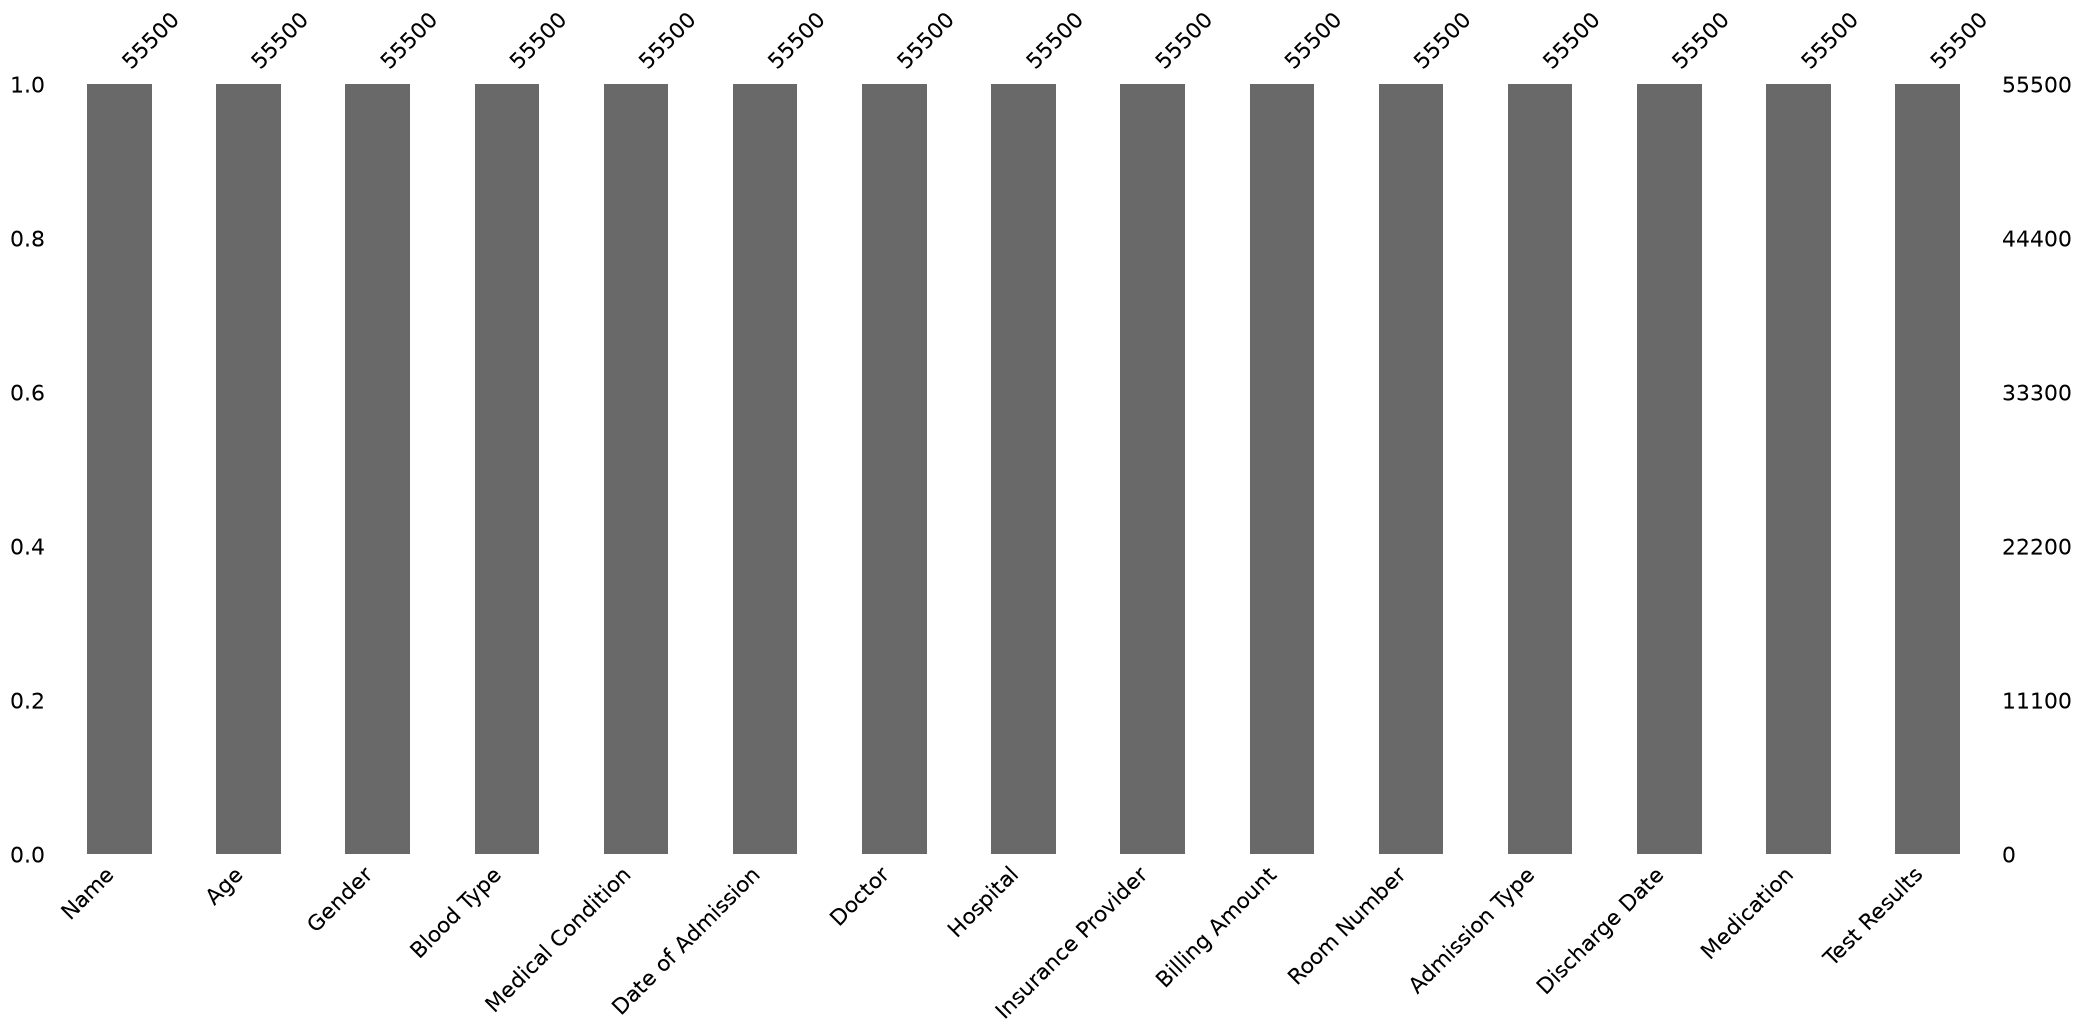

In [8]:
%matplotlib inline
msno.bar(df)

In [9]:
df["Name"]=df["Name"].str.title()
len_df_original = len(df)

In [10]:
df_wo_doublons = drop_duplicates_w_criterias(df)

print(f"La suppression des doublons a occasionné {len_df_original - len(df_wo_doublons)} lignes supprimées.\n"
      f"Environ {round((len_df_original - len(df_wo_doublons)) / len_df_original * 100,1)}% du fichier a donc été affecté.")

La suppression des doublons a occasionné 11000 lignes supprimées.
Environ 19.8% du fichier a donc été affecté.


In [11]:
df_wo_doublons


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44495,Carl Chandler,33,Female,AB-,Cancer,2020-09-25,Shannon Morales,Avery LLC,Aetna,46865.374640,306,Urgent,2020-10-15,Penicillin,Inconclusive
44496,Joseph Paul,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.348916,256,Emergency,2022-07-09,Paracetamol,Inconclusive
44497,Bradley Daniel,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.582493,463,Elective,2020-04-17,Aspirin,Abnormal
44498,Lisa Simpson,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.147064,411,Elective,2023-09-22,Aspirin,Abnormal


In [12]:
new_cols_name = format_header(df)
df_wo_doublons.rename(columns = new_cols_name, inplace=True)

df_wo_doublons

,Name,Age,Gender,BloodType,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44495,Carl Chandler,33,Female,AB-,Cancer,2020-09-25,Shannon Morales,Avery LLC,Aetna,46865.374640,306,Urgent,2020-10-15,Penicillin,Inconclusive
44496,Joseph Paul,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.348916,256,Emergency,2022-07-09,Paracetamol,Inconclusive
44497,Bradley Daniel,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.582493,463,Elective,2020-04-17,Aspirin,Abnormal
44498,Lisa Simpson,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.147064,411,Elective,2023-09-22,Aspirin,Abnormal


In [28]:
test= df_wo_doublons.copy()
test

,Name,Age,Gender,BloodType,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44495,Carl Chandler,33,Female,AB-,Cancer,2020-09-25,Shannon Morales,Avery LLC,Aetna,46865.374640,306,Urgent,2020-10-15,Penicillin,Inconclusive
44496,Joseph Paul,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.348916,256,Emergency,2022-07-09,Paracetamol,Inconclusive
44497,Bradley Daniel,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.582493,463,Elective,2020-04-17,Aspirin,Abnormal
44498,Lisa Simpson,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.147064,411,Elective,2023-09-22,Aspirin,Abnormal


In [32]:
test[["Prenom","Nom"]] = test["Name"].apply(
    lambda name: pd.Series(normalize_name(name))
)
test

,Name,Age,Gender,BloodType,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults,Prenom,Nom
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,bobby,jackson
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,leslie,terry
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,danny,smith
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,andrew,watts
4,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,emily,johnson
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44495,Carl Chandler,33,Female,AB-,Cancer,2020-09-25,Shannon Morales,Avery LLC,Aetna,46865.374640,306,Urgent,2020-10-15,Penicillin,Inconclusive,carl,chandler
44496,Joseph Paul,64,Male,O+,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.348916,256,Emergency,2022-07-09,Paracetamol,Inconclusive,joseph,paul
44497,Bradley Daniel,69,Male,B+,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.582493,463,Elective,2020-04-17,Aspirin,Abnormal,bradley,daniel
44498,Lisa Simpson,73,Male,O-,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.147064,411,Elective,2023-09-22,Aspirin,Abnormal,lisa,simpson


In [13]:
df_wo_doublons[df_wo_doublons[["Name","Gender","BloodType","Age"]].duplicated(keep=False)].loc[df_wo_doublons["Name"]=="Tina Griffin"]

,Name,Age,Gender,BloodType,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults
85,Tina Griffin,49,Male,B+,Cancer,2022-06-17,Jessica Cruz,Inc Ford,Medicare,25302.112634,268,Elective,2022-06-28,Penicillin,Abnormal
2427,Tina Griffin,49,Male,B+,Obesity,2023-06-07,Miss Mary Russell,"Vazquez, Coleman and Wallace",Cigna,44117.415743,461,Emergency,2023-06-14,Lipitor,Normal


In [14]:
unique_person = (
    df_wo_doublons[
        ~df_wo_doublons[["Name", "Gender", "BloodType", "Age"]]
        .duplicated()
    ]
    [["Name", "Gender", "BloodType", "Age"]]
    .reset_index(drop=True)
)

In [15]:
dbls = df_wo_doublons[df_wo_doublons[["Name", "Gender", "BloodType", "Age"]].duplicated(keep=False)]
dbls.loc[dbls["Name"]=="Ashley Garcia"]

,Name,Age,Gender,BloodType,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults
2237,Ashley Garcia,59,Male,O-,Cancer,2022-08-20,Jessica Evans DDS,Booth-Moore,Blue Cross,26795.687018,182,Emergency,2022-09-01,Lipitor,Abnormal
15323,Ashley Garcia,59,Male,O-,Cancer,2023-02-17,Jessica Rocha,Inc Green,Medicare,6520.649183,179,Elective,2023-02-24,Penicillin,Inconclusive


In [16]:
unique_person.drop_duplicates()

,Name,Gender,BloodType,Age
0,Bobby Jackson,Male,B-,30
1,Leslie Terry,Male,A+,62
2,Danny Smith,Female,A-,76
3,Andrew Watts,Female,O+,28
4,Emily Johnson,Male,A+,36
...,...,...,...,...
44481,Carl Chandler,Female,AB-,33
44482,Joseph Paul,Male,O+,64
44483,Bradley Daniel,Male,B+,69
44484,Lisa Simpson,Male,O-,73


In [17]:
mr_mme = unique_person['Name'].str.split()
mask = [len(ind)>2 for ind in mr_mme]
unique_person["Name"][mask]

14        Ms. Natalie Gamble
16       Mrs. Jamie Campbell
22       Dr. Eileen Thompson
26         Mr. Kenneth Moore
41             Mr. Eric Lane
                ...         
44357        Dr. Hector Tate
44359      Mr. Steven Hudson
44422      Karen Kennedy Dvm
44464        Derek Patel Dvm
44469     Dr. Kristi Fuentes
Name: Name, Length: 1710, dtype: str

In [18]:
unique_person.loc[unique_person["Name"]=="Dr. Kristi Fuentes"]

,Name,Gender,BloodType,Age
44469,Dr. Kristi Fuentes,Male,AB-,55


In [19]:
patient_columns = ["Name", "Gender", "BloodType", "Age"]
insurance_counts = (
    df_wo_doublons.groupby(patient_columns)["InsuranceProvider"]
      .nunique(dropna=False)
)

print(insurance_counts[insurance_counts > 1])

Name              Gender  BloodType  Age
Angela Brown      Male    O+         67     2
Ashley Garcia     Male    O-         59     2
Cody Jones        Male    A-         53     2
Gregory Jones     Female  A+         74     2
James Miller      Male    A+         46     2
John Johnson      Male    O-         37     2
John Smith        Male    AB-        45     2
Matthew Gonzalez  Female  B-         44     2
Michael Jones     Female  AB-        24     2
Paul Watson       Female  O-         45     2
Scott Martinez    Female  B-         65     2
Stephanie Garcia  Female  AB+        74     2
Tina Griffin      Male    B+         49     2
Name: InsuranceProvider, dtype: int64


### Ecriture de la collection Patients

In [20]:
try:
    uri = "mongodb://localhost:27017/"
    client = MongoClient(uri)

    database = client["medical"]
    collection = database["patients"]

    operations = [InsertOne(to_patient(row)) for index, row in unique_person.iterrows()]
    res = collection.bulk_write(operations)
    print("Ecriture des patients terminée ? ", res.acknowledged)

    client.close()

except Exception as e:
    raise Exception(
        "The following error occurred: ", e)

Ecriture des patients terminée ?  True


In [21]:
try:
    uri = "mongodb://localhost:27017/"
    client = MongoClient(uri)

    database = client["medical"]
    collection = database["patients"]
    
    print("Récupération de la table des patients...")
    patients_db = pd.DataFrame(
        collection.find({})
    ).rename(columns={"_id":"PatientId"})
    print("Table récupérée")
    client.close()
except Exception as e:
    raise Exception(
        "The following exception occured : ", e
    )

Récupération de la table des patients...
Table récupérée


In [22]:
patients_db

,PatientId,Name,Gender,BloodType,Age
0,6ad0936e3a64586d9d96bb90,Bobby Jackson,Male,B-,30
1,6ad0936e3a64586d9d96bb91,Leslie Terry,Male,A+,62
2,6ad0936e3a64586d9d96bb92,Danny Smith,Female,A-,76
3,6ad0936e3a64586d9d96bb93,Andrew Watts,Female,O+,28
4,6ad0936e3a64586d9d96bb94,Emily Johnson,Male,A+,36
...,...,...,...,...,...
44481,6ad0936f3a64586d9d976951,Carl Chandler,Female,AB-,33
44482,6ad0936f3a64586d9d976952,Joseph Paul,Male,O+,64
44483,6ad0936f3a64586d9d976953,Bradley Daniel,Male,B+,69
44484,6ad0936f3a64586d9d976954,Lisa Simpson,Male,O-,73


In [23]:
admissions_cols = [
    "MedicalCondition", "DateOfAdmission",
    "Doctor", "Hospital",
    "InsuranceProvider", "BillingAmount",
    "RoomNumber", "AdmissionType",
    "DischargeDate", "Medication",
    "TestResults", "PatientId"
]


admissions_df = pd.merge(
    df_wo_doublons, patients_db, on=["Name", "Gender", "BloodType", "Age"]
    )[admissions_cols]

admissions_df

,MedicalCondition,DateOfAdmission,Doctor,Hospital,InsuranceProvider,BillingAmount,RoomNumber,AdmissionType,DischargeDate,Medication,TestResults,PatientId
0,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,6ad0936e3a64586d9d96bb90
1,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6ad0936e3a64586d9d96bb91
2,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,6ad0936e3a64586d9d96bb92
3,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,6ad0936e3a64586d9d96bb93
4,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,6ad0936e3a64586d9d96bb94
...,...,...,...,...,...,...,...,...,...,...,...,...
44495,Cancer,2020-09-25,Shannon Morales,Avery LLC,Aetna,46865.374640,306,Urgent,2020-10-15,Penicillin,Inconclusive,6ad0936f3a64586d9d976951
44496,Hypertension,2022-06-28,Arthur Fleming,"and Williams, Brown Mckenzie",Blue Cross,24747.348916,256,Emergency,2022-07-09,Paracetamol,Inconclusive,6ad0936f3a64586d9d976952
44497,Cancer,2020-04-04,Mark Moore,Wise Ltd,Medicare,40657.582493,463,Elective,2020-04-17,Aspirin,Abnormal,6ad0936f3a64586d9d976953
44498,Cancer,2023-09-08,Deborah Sutton,"Moreno Murphy, Griffith and",Blue Cross,8441.147064,411,Elective,2023-09-22,Aspirin,Abnormal,6ad0936f3a64586d9d976954


In [24]:
try:
    uri = "mongodb://localhost:27017/"
    client = MongoClient(uri)

    database = client["medical"]
    collection = database["admissions"]
    print("Ecriture des admissions en cours")
    operations = [InsertOne(to_admission(row)) for index, row in admissions_df.iterrows()]
    res = collection.bulk_write(operations)
    print("Ecriture des admissions terminée ? ", res.acknowledged)
except Exception as e:
    print("The following exception occured :", e)    

Ecriture des admissions en cours
Ecriture des admissions terminée ?  True
